# 04 - Feature Combinations and Group Importance

**Goal:** Find out whether the 505 handcrafted numbers carry signal *together*, which feature groups add complementary information, and whether a compact group set can match the full set.

This notebook only evaluates features that are already extracted. It does not add new features, and it only uses 2019 LA **train** and **dev**. The 2019 **eval** and all 2021 data stay untouched.


## Contents

1. Setup
2. Loading the Summary Features
3. Metrics and Model Helpers
4. Choosing Regularization
5. Baselines
6. Each Feature Group Alone
7. Add and Remove Groups
8. Greedy Group Selection
9. Group Permutation Importance
10. Attack Breakdown
11. Summary


## Setup

The notebook imports the project code from `src/`, then uses pandas and scikit-learn for the evaluation. Audio settings still come from `src/config.py`, so the clip length matches the rest of the project.


In [1]:
# Re-import edited files from src/ automatically, and show plots inside the notebook
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Let the notebook import our shared code from src/
import sys
sys.path.insert(0, "../src")

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from config import CLIP_SECONDS, FEATURES_DIR, N_LFCC, N_MELS, N_MFCC
from data import load_features
from features import FEATURES

# Keep output readable, but do not hide errors.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

REAL, FAKE = 0, 1
NAMES = {REAL: "real", FAKE: "fake"}
RANDOM_STATE = 0

print(f"clip length {CLIP_SECONDS:g}s | feature groups: {', '.join(FEATURES)}")


clip length 4s | feature groups: mfcc, lfcc, logmel, cqt, spectral, pitch, jitter_shimmer, noise


## Loading the Summary Features

Each feature grid is reduced to one row per clip, using the same rule as notebook 02:

- average over time,
- spread over time,
- plus the voiced fraction for pitch.

This gives 505 numbers per clip. The raw grids are discarded after each group so memory stays manageable.


In [2]:
ROW_NAMES = {
    "mfcc": [f"{p}mfcc{i}" for p in ("", "d_", "dd_") for i in range(N_MFCC)],
    "lfcc": [f"lfcc{i}" for i in range(N_LFCC)],
    "logmel": [f"logmel{i}" for i in range(N_MELS)],
    "cqt": [f"cqt{i}" for i in range(84)],
    "spectral": ["centroid", "flatness", "rolloff", "flux"],
    "pitch": ["f0", "voiced_prob"],
    "jitter_shimmer": ["jitter", "shimmer"],
    "noise": ["noise_mean_db", "noise_std_db"],
}


def summarize(feature, x):
    """One table row per clip. Columns are named "<feature>:<row>:<mean or std>".."""
    names = ROW_NAMES[feature]
    if x.ndim == 2:  # already one number per clip
        df = pd.DataFrame(x, columns=[f"{feature}:{n}" for n in names])
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # pitch is NaN where there is no pitch
            mean, std = np.nanmean(x, axis=2), np.nanstd(x, axis=2)

        cols = {}
        for i, n in enumerate(names):
            cols[f"{feature}:{n}:mean"] = mean[:, i]
            cols[f"{feature}:{n}:std"] = std[:, i]
        if feature == "pitch":
            cols["pitch:voiced_fraction"] = (~np.isnan(x[:, 0, :])).mean(axis=1)
        df = pd.DataFrame(cols)

    return df.replace([np.inf, -np.inf], np.nan)


def build_summary(split):
    """Load every feature group for one split and return the 505-number table."""
    parts = []
    labels = None
    for feature in FEATURES:
        x, labels = load_features(feature, split, CLIP_SECONDS)
        parts.append(summarize(feature, x))
        print(f"  {feature:15s} {x.shape}", flush=True)
    table = pd.concat(parts, axis=1).astype(np.float32)
    return table, labels


In [3]:
print("loading train features...")
X_train, meta_train = build_summary("train")
print("loading dev features...")
X_dev, meta_dev = build_summary("dev")

y_train = meta_train["label"].to_numpy()
y_dev = meta_dev["label"].to_numpy()
groups_train = meta_train["speaker"].to_numpy()

assert list(X_train.columns) == list(X_dev.columns), "train and dev columns differ"
assert len(X_train) == len(meta_train) and len(X_dev) == len(meta_dev)
assert set(np.unique(y_train)) == {REAL, FAKE} and set(np.unique(y_dev)) == {REAL, FAKE}

print()
print(f"train: {X_train.shape[0]:,} clips x {X_train.shape[1]:,} numbers")
print(f"dev:   {X_dev.shape[0]:,} clips x {X_dev.shape[1]:,} numbers")
print(f"train labels: real {(y_train == REAL).sum():,} | fake {(y_train == FAKE).sum():,}")
print(f"dev labels:   real {(y_dev == REAL).sum():,} | fake {(y_dev == FAKE).sum():,}")
print(f"train speakers: {meta_train['speaker'].nunique()} | dev speakers: {meta_dev['speaker'].nunique()}")
print(f"train attacks: {sorted(meta_train['system'].unique())}")
print(f"dev attacks:   {sorted(meta_dev['system'].unique())}")
print()
missing = pd.DataFrame({
    "train missing": X_train.isna().mean().groupby([c.split(":")[0] for c in X_train.columns]).mean(),
    "dev missing": X_dev.isna().mean().groupby([c.split(":")[0] for c in X_dev.columns]).mean(),
}).loc[list(FEATURES)]
missing.round(4)


loading train features...


  mfcc            (25380, 60, 126)


  lfcc            (25380, 20, 126)


  logmel          (25380, 80, 126)


  cqt             (25380, 84, 126)


...

  pitch           (24844, 2, 126)


  jitter_shimmer  (24844, 2)


  noise           (24844, 2)



train: 25,380 clips x 505 numbers
dev:   24,844 clips x 505 numbers
train labels: real 2,580 | fake 22,800
dev labels:   real 2,548 | fake 22,296
train speakers: 20 | dev speakers: 20
train attacks: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
dev attacks:   ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']



,train missing,dev missing
mfcc,0.000,0.0000
lfcc,0.000,0.0000
logmel,0.000,0.0000
cqt,0.000,0.0000
spectral,0.000,0.0000
pitch,0.001,0.0012
jitter_shimmer,0.000,0.0000
noise,0.000,0.0000


## Metrics and Model Helpers

Two scores matter here:

- **AUC** measures how well the scores rank fake above real.
- **EER** is the equal error rate, the standard ASVspoof-style summary. Lower is better.

A model that is right about the majority class can still have a poor AUC/EER, which matters because the training data is about 9 fake clips for every real one. All models below use class weights instead of resampling.

The confidence intervals use a stratified bootstrap, so each resample keeps the real/fake balance.


In [4]:
def eer_score(y_true, scores):
    """Equal error rate: where false accept and false reject rates meet."""
    fpr, tpr, _ = roc_curve(y_true, scores)
    fnr = 1.0 - tpr
    i = np.nanargmin(np.abs(fpr - fnr))
    return float((fpr[i] + fnr[i]) / 2.0)


def bootstrap_ci(y_true, scores, metric, n_boot=300, seed=0):
    """95% CI, resampling separately within each class."""
    rng = np.random.default_rng(seed)
    idx_real = np.flatnonzero(y_true == REAL)
    idx_fake = np.flatnonzero(y_true == FAKE)
    values = []
    for _ in range(n_boot):
        idx = np.concatenate([
            rng.choice(idx_real, size=len(idx_real), replace=True),
            rng.choice(idx_fake, size=len(idx_fake), replace=True),
        ])
        values.append(metric(y_true[idx], scores[idx]))
    return tuple(np.percentile(values, [2.5, 97.5]))


def metrics_with_ci(y_true, scores, n_boot=300, seed=0):
    """AUC and EER plus 95% bootstrap intervals."""
    auc = roc_auc_score(y_true, scores)
    eer = eer_score(y_true, scores)
    auc_ci = bootstrap_ci(y_true, scores, roc_auc_score, n_boot=n_boot, seed=seed)
    eer_ci = bootstrap_ci(y_true, scores, eer_score, n_boot=n_boot, seed=seed + 1)
    return {
        "auc": float(auc),
        "eer": float(eer),
        "auc_95": f"{auc_ci[0]:.3f}-{auc_ci[1]:.3f}",
        "eer_95": f"{eer_ci[0]:.3f}-{eer_ci[1]:.3f}",
    }


def univariate_aucs(table, y):
    """AUC for every column on its own."""
    out = {}
    for col in table.columns:
        v = table[col].to_numpy()
        ok = np.isfinite(v)
        if ok.any() and len(np.unique(y[ok])) == 2:
            out[col] = roc_auc_score(y[ok], v[ok])
    return pd.Series(out)


def logistic_pipeline(C):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            C=C,
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE,
        )),
    ])


def hgb_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            early_stopping=False,  # avoid a non-group-aware internal split
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])


def cv_auc_for_cols(factory, cols, X, y, folds):
    """AUC per fold for one column set."""
    aucs = []
    for tr, va in folds:
        model = factory()
        model.fit(X.iloc[tr][cols], y[tr])
        scores = model.predict_proba(X.iloc[va][cols])[:, 1]
        aucs.append(roc_auc_score(y[va], scores))
    return np.array(aucs)


folds = list(StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
).split(X_train, y_train, groups_train))

fold_table = pd.DataFrame([
    {
        "fold": i,
        "train": len(tr),
        "validation": len(va),
        "train real": int((y_train[tr] == REAL).sum()),
        "validation real": int((y_train[va] == REAL).sum()),
    }
    for i, (tr, va) in enumerate(folds)
])
fold_table


,fold,train,validation,train real,validation real
0,0,20278,5102,2062,518
1,1,20278,5102,2062,518
2,2,20278,5102,2062,518
3,3,20343,5037,2067,513
4,4,20343,5037,2067,513


## Choosing Regularization

The logistic model is tuned once on the full 505-number table using grouped cross-validation on train. The chosen `C` is then reused for every group and ablation, so differences come from the feature set rather than from tuning each experiment differently.

The nonlinear model uses fixed, reasonable defaults. It is here to check whether interactions beyond a linear combination help.


In [5]:
C_GRID = [0.01, 0.1, 1.0, 10.0]
all_cols = list(X_train.columns)

C_rows = []
for C in C_GRID:
    aucs = cv_auc_for_cols(lambda C=C: logistic_pipeline(C), all_cols, X_train, y_train, folds)
    C_rows.append({
        "C": C,
        "cv_auc_mean": float(aucs.mean()),
        "cv_auc_std": float(aucs.std()),
        "cv_auc_min": float(aucs.min()),
        "cv_auc_max": float(aucs.max()),
    })
C_table = pd.DataFrame(C_rows)
best_C = float(C_table.loc[C_table["cv_auc_mean"].idxmax(), "C"])

hgb_cv_aucs = cv_auc_for_cols(hgb_pipeline, all_cols, X_train, y_train, folds)

print(f"selected C: {best_C:g}")
print(f"HGB grouped CV AUC: {hgb_cv_aucs.mean():.4f} +/- {hgb_cv_aucs.std():.4f}")
C_table.round(4)


selected C: 1
HGB grouped CV AUC: 0.9850 +/- 0.0105


,C,cv_auc_mean,cv_auc_std,cv_auc_min,cv_auc_max
0,0.01,0.9858,0.0076,0.9768,0.9996
1,0.10,0.9891,0.0066,0.9817,0.9998
2,1.00,0.9892,0.0071,0.9805,0.9999
3,10.00,0.9792,0.0166,0.9510,0.9996


## Baselines

These rows answer: how much signal is in one number, in LFCC alone, and in all 505 numbers together? The shuffled-label row is a control; it should collapse to about 0.5 AUC.


In [6]:
def fit_and_score(model, cols, Xtr, ytr, Xte):
    model.fit(Xtr[cols], ytr)
    scores = model.predict_proba(Xte[cols])[:, 1]
    return model, scores


def best_single_feature(Xtr, ytr, Xte, folds):
    """Select the best absolute-AUC column inside each training fold, then score it."""
    fold_aucs = []
    chosen = []
    for tr, va in folds:
        aucs = univariate_aucs(Xtr.iloc[tr], ytr[tr])
        best = (0.5 + (aucs - 0.5).abs()).idxmax()
        chosen.append(best)
        scores = Xtr.iloc[va][best].to_numpy()
        if aucs[best] < 0.5:
            scores = -scores
        ok = np.isfinite(scores)
        fold_aucs.append(roc_auc_score(ytr[va][ok], scores[ok]))

    aucs = univariate_aucs(Xtr, ytr)
    best = (0.5 + (aucs - 0.5).abs()).idxmax()
    scores = Xte[best].to_numpy()
    if aucs[best] < 0.5:
        scores = -scores
    return float(np.mean(fold_aucs)), float(np.std(fold_aucs)), best, scores


baseline_rows = []
baseline_rows.append({
    "model": "chance",
    "features": "-",
    "cv_auc": 0.5,
    "dev_auc": 0.5,
    "dev_eer": 0.5,
    "dev_auc_95": "-",
    "dev_eer_95": "-",
    "notes": "no information",
})

single_cv_mean, single_cv_std, single_best, single_scores = best_single_feature(
    X_train, y_train, X_dev, folds
)
single_metrics = metrics_with_ci(y_dev, single_scores)
baseline_rows.append({
    "model": "best single number",
    "features": "1 of 505",
    "cv_auc": single_cv_mean,
    "dev_auc": single_metrics["auc"],
    "dev_eer": single_metrics["eer"],
    "dev_auc_95": single_metrics["auc_95"],
    "dev_eer_95": single_metrics["eer_95"],
    "notes": f"{single_best} (CV std {single_cv_std:.3f})",
})

group_cols = {
    group: [c for c in all_cols if c.split(":")[0] == group]
    for group in FEATURES
}
lfcc_cols = group_cols["lfcc"]

lfcc_cv = cv_auc_for_cols(lambda: logistic_pipeline(best_C), lfcc_cols, X_train, y_train, folds)
lfcc_model, lfcc_scores = fit_and_score(logistic_pipeline(best_C), lfcc_cols, X_train, y_train, X_dev)
lfcc_metrics = metrics_with_ci(y_dev, lfcc_scores)
baseline_rows.append({
    "model": "LFCC only",
    "features": f"{len(lfcc_cols)} numbers",
    "cv_auc": float(lfcc_cv.mean()),
    "dev_auc": lfcc_metrics["auc"],
    "dev_eer": lfcc_metrics["eer"],
    "dev_auc_95": lfcc_metrics["auc_95"],
    "dev_eer_95": lfcc_metrics["eer_95"],
    "notes": "best-looking single group in notebook 02",
})

all_cv = cv_auc_for_cols(lambda: logistic_pipeline(best_C), all_cols, X_train, y_train, folds)
all_model, all_scores = fit_and_score(logistic_pipeline(best_C), all_cols, X_train, y_train, X_dev)
all_metrics = metrics_with_ci(y_dev, all_scores)
baseline_rows.append({
    "model": "all groups, logistic",
    "features": f"{len(all_cols)} numbers",
    "cv_auc": float(all_cv.mean()),
    "dev_auc": all_metrics["auc"],
    "dev_eer": all_metrics["eer"],
    "dev_auc_95": all_metrics["auc_95"],
    "dev_eer_95": all_metrics["eer_95"],
    "notes": "linear combination",
})

hgb_model, hgb_scores = fit_and_score(hgb_pipeline(), all_cols, X_train, y_train, X_dev)
hgb_metrics = metrics_with_ci(y_dev, hgb_scores)
baseline_rows.append({
    "model": "all groups, HGB",
    "features": f"{len(all_cols)} numbers",
    "cv_auc": float(hgb_cv_aucs.mean()),
    "dev_auc": hgb_metrics["auc"],
    "dev_eer": hgb_metrics["eer"],
    "dev_auc_95": hgb_metrics["auc_95"],
    "dev_eer_95": hgb_metrics["eer_95"],
    "notes": "nonlinear interactions",
})

rng = np.random.default_rng(2)
shuffled_aucs, shuffled_eers = [], []
for _ in range(3):
    shuffled_model, shuffled_scores = fit_and_score(
        logistic_pipeline(best_C), all_cols, X_train, rng.permutation(y_train), X_dev
    )
    shuffled_aucs.append(roc_auc_score(y_dev, shuffled_scores))
    shuffled_eers.append(eer_score(y_dev, shuffled_scores))
baseline_rows.append({
    "model": "shuffled train labels",
    "features": f"{len(all_cols)} numbers",
    "cv_auc": np.nan,
    "dev_auc": float(np.mean(shuffled_aucs)),
    "dev_eer": float(np.mean(shuffled_eers)),
    "dev_auc_95": "-",
    "dev_eer_95": "-",
    "notes": "control; should be near 0.5",
})

baseline_table = pd.DataFrame(baseline_rows)
baseline_table.round(4)


,model,features,cv_auc,dev_auc,dev_eer,dev_auc_95,dev_eer_95,notes
0,chance,-,0.5000,0.5000,0.5000,-,-,no information
1,best single number,1 of 505,0.7561,0.7310,0.3289,0.720-0.742,0.320-0.338,logmel:logmel79:mean (CV std 0.041)
2,LFCC only,40 numbers,0.9412,0.9589,0.1037,0.954-0.962,0.097-0.110,best-looking single group in notebook 02
3,"all groups, logistic",505 numbers,0.9892,0.9896,0.0541,0.988-0.991,0.050-0.058,linear combination
4,"all groups, HGB",505 numbers,0.9850,0.9913,0.0459,0.990-0.992,0.042-0.049,nonlinear interactions
5,shuffled train labels,505 numbers,NaN,0.4897,0.5098,-,-,control; should be near 0.5


## Each Feature Group Alone

This is the multivariate version of notebook 02: instead of ranking one number at a time, each whole group gets a model. It answers which group contains the most usable information on its own.


In [7]:
group_rows = []
for group, cols in group_cols.items():
    cv_aucs = cv_auc_for_cols(lambda: logistic_pipeline(best_C), cols, X_train, y_train, folds)
    model, scores = fit_and_score(logistic_pipeline(best_C), cols, X_train, y_train, X_dev)
    metrics = metrics_with_ci(y_dev, scores)
    group_rows.append({
        "group": group,
        "n_numbers": len(cols),
        "cv_auc": float(cv_aucs.mean()),
        "cv_auc_std": float(cv_aucs.std()),
        "dev_auc": metrics["auc"],
        "dev_eer": metrics["eer"],
        "dev_auc_95": metrics["auc_95"],
        "dev_eer_95": metrics["eer_95"],
    })

group_table = pd.DataFrame(group_rows).sort_values("dev_auc", ascending=False).reset_index(drop=True)
group_table.round(4)


,group,n_numbers,cv_auc,cv_auc_std,dev_auc,dev_eer,dev_auc_95,dev_eer_95
0,lfcc,40,0.9412,0.0296,0.9589,0.1037,0.954-0.962,0.097-0.110
1,logmel,160,0.8587,0.0486,0.8874,0.1938,0.881-0.894,0.186-0.201
2,mfcc,120,0.8422,0.0503,0.8293,0.2539,0.822-0.837,0.246-0.262
3,cqt,168,0.7941,0.0501,0.7475,0.3174,0.737-0.758,0.309-0.327
4,spectral,8,0.7421,0.0578,0.7384,0.3246,0.729-0.748,0.316-0.334
5,jitter_shimmer,2,0.7316,0.0262,0.7181,0.3305,0.707-0.728,0.321-0.340
6,pitch,5,0.6769,0.0321,0.6414,0.3996,0.630-0.652,0.389-0.409
7,noise,2,0.5525,0.0281,0.5246,0.4826,0.513-0.535,0.474-0.493


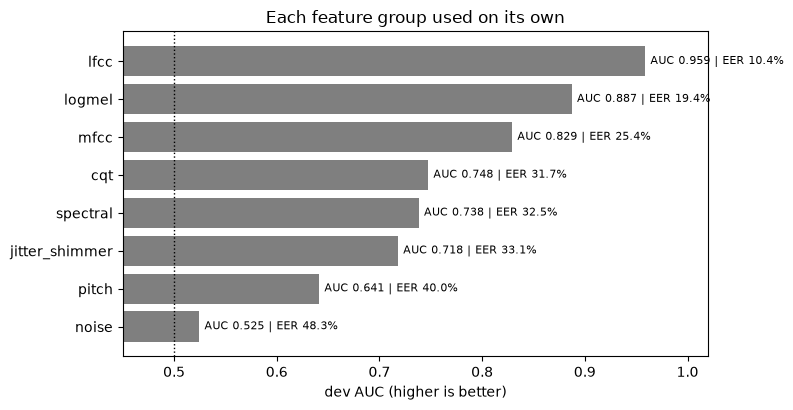

In [8]:
plot = group_table.sort_values("dev_auc")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(plot["group"], plot["dev_auc"], color="tab:gray")
ax.axvline(0.5, color="black", linestyle=":", linewidth=1)
ax.set_xlabel("dev AUC (higher is better)")
ax.set_title("Each feature group used on its own")
for i, (auc, eer) in enumerate(zip(plot["dev_auc"], plot["dev_eer"])):
    ax.text(auc + 0.005, i, f"AUC {auc:.3f} | EER {eer:.1%}", va="center", fontsize=8)
ax.set_xlim(0.45, 1.02)
plt.tight_layout()


## Add and Remove Groups

The group-alone table can hide complementarity. These two tables ask:

- **LFCC + one group:** does the group add anything to the strongest group?
- **All minus one group:** does the model lose anything when that group is removed?

A negative `delta_auc` or positive `delta_eer` means the group is not helping in that setting.


In [9]:
def eval_logistic(cols):
    model, scores = fit_and_score(logistic_pipeline(best_C), cols, X_train, y_train, X_dev)
    return model, scores, roc_auc_score(y_dev, scores), eer_score(y_dev, scores)


add_rows = []
for group in FEATURES:
    if group == "lfcc":
        continue
    cols = lfcc_cols + group_cols[group]
    _, _, auc, eer = eval_logistic(cols)
    add_rows.append({
        "experiment": f"LFCC + {group}",
        "added_group": group,
        "n_numbers": len(cols),
        "dev_auc": float(auc),
        "dev_eer": float(eer),
        "delta_auc_vs_lfcc": float(auc - lfcc_metrics["auc"]),
        "delta_eer_vs_lfcc": float(eer - lfcc_metrics["eer"]),
    })

remove_rows = []
for group in FEATURES:
    cols = [c for c in all_cols if c.split(":")[0] != group]
    _, _, auc, eer = eval_logistic(cols)
    remove_rows.append({
        "experiment": f"all minus {group}",
        "removed_group": group,
        "n_numbers": len(cols),
        "dev_auc": float(auc),
        "dev_eer": float(eer),
        "delta_auc_vs_all": float(auc - all_metrics["auc"]),
        "delta_eer_vs_all": float(eer - all_metrics["eer"]),
    })

add_table = pd.DataFrame(add_rows).sort_values("dev_auc", ascending=False).reset_index(drop=True)
remove_table = pd.DataFrame(remove_rows).sort_values("delta_auc_vs_all", ascending=False).reset_index(drop=True)

print("LFCC alone:")
print(f"  AUC {lfcc_metrics['auc']:.4f} | EER {lfcc_metrics['eer']:.3f}")
print("all groups:")
print(f"  AUC {all_metrics['auc']:.4f} | EER {all_metrics['eer']:.3f}")
print()
print("best additions to LFCC")
display(add_table.head(8).round(4))
print("largest losses when removed")
display(remove_table.head(8).round(4))


LFCC alone:
  AUC 0.9589 | EER 0.104
all groups:
  AUC 0.9896 | EER 0.054

best additions to LFCC


,experiment,added_group,n_numbers,dev_auc,dev_eer,delta_auc_vs_lfcc,delta_eer_vs_lfcc
0,LFCC + cqt,cqt,208,0.9847,0.0664,0.0258,-0.0373
1,LFCC + logmel,logmel,200,0.9831,0.0715,0.0243,-0.0322
2,LFCC + mfcc,mfcc,160,0.9759,0.0842,0.0171,-0.0195
3,LFCC + jitter_shimmer,jitter_shimmer,42,0.9645,0.0914,0.0056,-0.0123
4,LFCC + pitch,pitch,45,0.9609,0.1036,0.0020,-0.0001
5,LFCC + noise,noise,42,0.9596,0.1043,0.0008,0.0006
6,LFCC + spectral,spectral,48,0.9581,0.1027,-0.0008,-0.0010


largest losses when removed


,experiment,removed_group,n_numbers,dev_auc,dev_eer,delta_auc_vs_all,delta_eer_vs_all
0,all minus mfcc,mfcc,385,0.9920,0.0470,0.0024,-0.0071
1,all minus logmel,logmel,345,0.9909,0.0503,0.0012,-0.0038
2,all minus spectral,spectral,497,0.9895,0.0551,-0.0001,0.0010
3,all minus jitter_shimmer,jitter_shimmer,503,0.9894,0.0543,-0.0002,0.0002
4,all minus noise,noise,503,0.9891,0.0553,-0.0006,0.0013
5,all minus pitch,pitch,500,0.9888,0.0562,-0.0008,0.0021
6,all minus cqt,cqt,337,0.9870,0.0615,-0.0026,0.0074
7,all minus lfcc,lfcc,465,0.9833,0.0680,-0.0063,0.0139


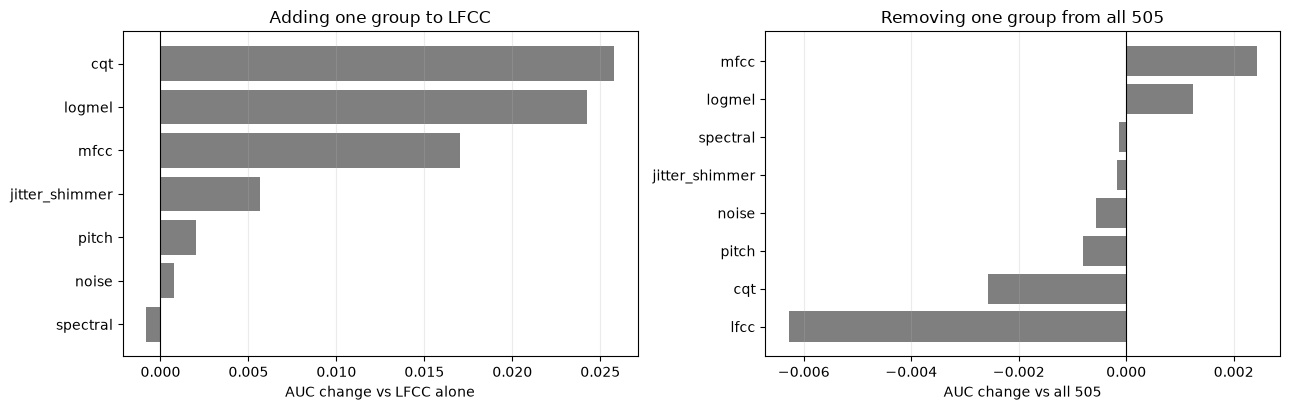

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

add_plot = add_table.sort_values("delta_auc_vs_lfcc")
axes[0].barh(add_plot["added_group"], add_plot["delta_auc_vs_lfcc"], color="tab:gray")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("AUC change vs LFCC alone")
axes[0].set_title("Adding one group to LFCC")

remove_plot = remove_table.sort_values("delta_auc_vs_all")
axes[1].barh(remove_plot["removed_group"], remove_plot["delta_auc_vs_all"], color="tab:gray")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("AUC change vs all 505")
axes[1].set_title("Removing one group from all 505")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()


## Greedy Group Selection

This searches for a compact set of groups using **train cross-validation only**. It starts with LFCC, repeatedly adds the group that gives the largest CV AUC gain, and stops when the gain is negligible. The selected set is then scored on dev once.


In [11]:
selected = ["lfcc"]
remaining = [g for g in FEATURES if g != "lfcc"]
current_auc = float(cv_auc_for_cols(
    lambda: logistic_pipeline(best_C), lfcc_cols, X_train, y_train, folds
).mean())

greedy_rows = [{
    "step": 0,
    "added": "lfcc (start)",
    "groups": ", ".join(selected),
    "cv_auc": current_auc,
}]

while remaining:
    candidates = []
    for group in remaining:
        cols = [c for c in all_cols if c.split(":")[0] in selected + [group]]
        aucs = cv_auc_for_cols(lambda: logistic_pipeline(best_C), cols, X_train, y_train, folds)
        candidates.append((float(aucs.mean()), group, float(aucs.std())))

    best_auc, best_group, best_std = max(candidates, key=lambda item: item[0])
    if best_auc <= current_auc + 5e-4:
        print(f"stop: best remaining gain is {best_auc - current_auc:+.4f} AUC ({best_group})")
        break

    selected.append(best_group)
    remaining.remove(best_group)
    current_auc = best_auc
    greedy_rows.append({
        "step": len(selected) - 1,
        "added": f"{best_group} (+{best_std:.3f} std)",
        "groups": ", ".join(selected),
        "cv_auc": current_auc,
    })
    print(f"add {best_group:15s} -> CV AUC {current_auc:.4f}")

greedy_table = pd.DataFrame(greedy_rows)

selected_cols = [c for c in all_cols if c.split(":")[0] in selected]
selected_model, selected_scores = fit_and_score(
    logistic_pipeline(best_C), selected_cols, X_train, y_train, X_dev
)
selected_metrics = metrics_with_ci(y_dev, selected_scores)

selected_hgb_model, selected_hgb_scores = fit_and_score(
    hgb_pipeline(), selected_cols, X_train, y_train, X_dev
)
selected_hgb_metrics = metrics_with_ci(y_dev, selected_hgb_scores)

selected_table = pd.DataFrame([
    {
        "model": "selected groups, logistic",
        "groups": ", ".join(selected),
        "n_numbers": len(selected_cols),
        "dev_auc": selected_metrics["auc"],
        "dev_eer": selected_metrics["eer"],
        "dev_auc_95": selected_metrics["auc_95"],
        "dev_eer_95": selected_metrics["eer_95"],
    },
    {
        "model": "selected groups, HGB",
        "groups": ", ".join(selected),
        "n_numbers": len(selected_cols),
        "dev_auc": selected_hgb_metrics["auc"],
        "dev_eer": selected_hgb_metrics["eer"],
        "dev_auc_95": selected_hgb_metrics["auc_95"],
        "dev_eer_95": selected_hgb_metrics["eer_95"],
    },
])

print()
print("selected groups:", ", ".join(selected))
display(greedy_table.round(4))
selected_table.round(4)


add cqt             -> CV AUC 0.9792


add logmel          -> CV AUC 0.9881


add jitter_shimmer  -> CV AUC 0.9906


add spectral        -> CV AUC 0.9919


add pitch           -> CV AUC 0.9925


stop: best remaining gain is +0.0001 AUC (noise)



selected groups: lfcc, cqt, logmel, jitter_shimmer, spectral, pitch


,step,added,groups,cv_auc
0,0,lfcc (start),lfcc,0.9412
1,1,cqt (+0.010 std),"lfcc, cqt",0.9792
2,2,logmel (+0.007 std),"lfcc, cqt, logmel",0.9881
3,3,jitter_shimmer (+0.006 std),"lfcc, cqt, logmel, jitter_shimmer",0.9906
4,4,spectral (+0.005 std),"lfcc, cqt, logmel, jitter_shimmer, spectral",0.9919
5,5,pitch (+0.005 std),"lfcc, cqt, logmel, jitter_shimmer, spectral, p...",0.9925


,model,groups,n_numbers,dev_auc,dev_eer,dev_auc_95,dev_eer_95
0,"selected groups, logistic","lfcc, cqt, logmel, jitter_shimmer, spectral, p...",383,0.9926,0.0463,0.992-0.993,0.041-0.050
1,"selected groups, HGB","lfcc, cqt, logmel, jitter_shimmer, spectral, p...",383,0.9902,0.0517,0.988-0.992,0.046-0.056


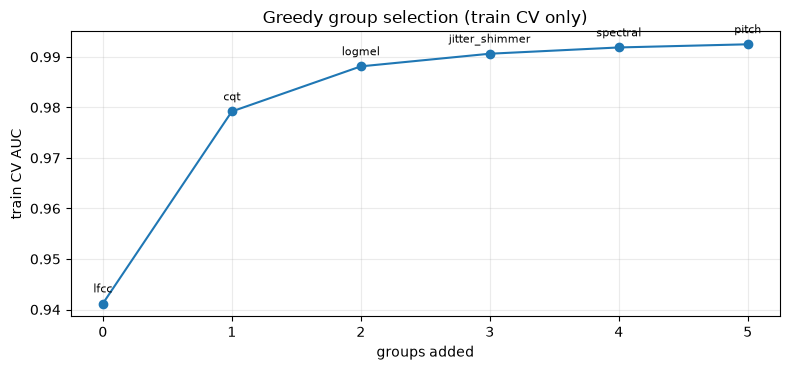

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(greedy_table["step"], greedy_table["cv_auc"], marker="o")
for _, row in greedy_table.iterrows():
    ax.annotate(row["added"].split(" (")[0], (row["step"], row["cv_auc"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("groups added")
ax.set_ylabel("train CV AUC")
ax.set_title("Greedy group selection (train CV only)")
ax.grid(alpha=0.25)
plt.tight_layout()


## Group Permutation Importance

This uses the all-505 logistic model. Each group is shuffled **jointly** on dev, which breaks its relationship with the label while keeping the within-group correlation structure. The drop in AUC is the group's contribution in the presence of the other groups.


In [13]:
base_auc = all_metrics["auc"]
base_eer = all_metrics["eer"]
rng = np.random.default_rng(1)

perm_rows = []
for group, cols in group_cols.items():
    auc_drops = []
    eer_increases = []
    for _ in range(10):
        X_shuffled = X_dev.copy()
        order = rng.permutation(len(X_shuffled))
        X_shuffled[cols] = X_shuffled[cols].to_numpy()[order]
        scores = all_model.predict_proba(X_shuffled)[:, 1]
        auc_drops.append(base_auc - roc_auc_score(y_dev, scores))
        eer_increases.append(eer_score(y_dev, scores) - base_eer)
    perm_rows.append({
        "group": group,
        "auc_drop_mean": float(np.mean(auc_drops)),
        "auc_drop_std": float(np.std(auc_drops)),
        "eer_increase_mean": float(np.mean(eer_increases)),
        "eer_increase_std": float(np.std(eer_increases)),
    })

perm_table = pd.DataFrame(perm_rows).sort_values("auc_drop_mean", ascending=False).reset_index(drop=True)
perm_table.round(4)


,group,auc_drop_mean,auc_drop_std,eer_increase_mean,eer_increase_std
0,lfcc,0.3178,0.0038,0.3178,0.0033
1,cqt,0.2459,0.0049,0.2628,0.0046
2,logmel,0.2265,0.0034,0.2486,0.0040
3,mfcc,0.0483,0.0011,0.0780,0.0021
4,jitter_shimmer,0.0069,0.0003,0.0150,0.0011
5,spectral,0.0052,0.0004,0.0104,0.0011
6,noise,0.0008,0.0001,0.0025,0.0007
7,pitch,-0.0007,0.0001,-0.0018,0.0009


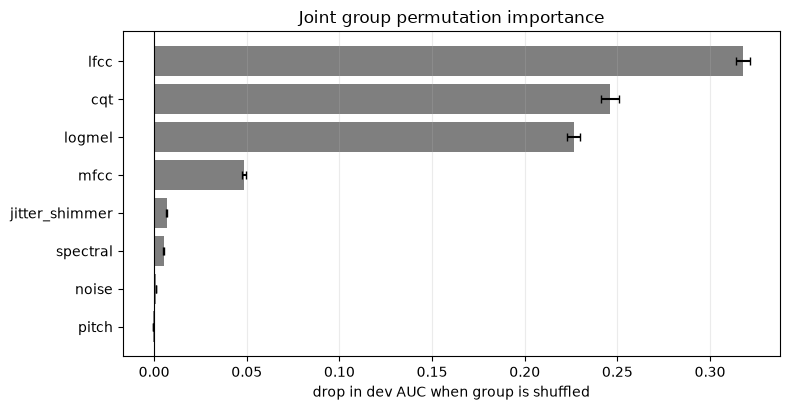

In [14]:
plot = perm_table.sort_values("auc_drop_mean")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(plot["group"], plot["auc_drop_mean"], xerr=plot["auc_drop_std"], color="tab:gray", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("drop in dev AUC when group is shuffled")
ax.set_title("Joint group permutation importance")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()


## Attack Breakdown

Dev contains the same attacks as train (A01-A06), so these numbers are easier than the final eval set. They still show whether the model is relying on one attack or is spread across all of them.


In [15]:
attack_rows = []
for attack in sorted(a for a in meta_dev["system"].unique() if a != "-"):
    mask = (meta_dev["system"] == attack) | (meta_dev["label"] == REAL)
    y_sub = y_dev[mask]
    scores_sub = all_scores[mask]
    attack_rows.append({
        "attack": attack,
        "n_real": int((y_sub == REAL).sum()),
        "n_fake": int((y_sub == FAKE).sum()),
        "auc": float(roc_auc_score(y_sub, scores_sub)),
        "eer": float(eer_score(y_sub, scores_sub)),
    })

attack_rows.append({
    "attack": "all dev",
    "n_real": int((y_dev == REAL).sum()),
    "n_fake": int((y_dev == FAKE).sum()),
    "auc": float(all_metrics["auc"]),
    "eer": float(all_metrics["eer"]),
})
attack_table = pd.DataFrame(attack_rows)
attack_table.round(4)


,attack,n_real,n_fake,auc,eer
0,A01,2548,3716,0.9994,0.0121
1,A02,2548,3716,0.9868,0.0602
2,A03,2548,3716,0.9780,0.0859
3,A04,2548,3716,0.9979,0.0220
4,A05,2548,3716,0.9758,0.0873
5,A06,2548,3716,0.9998,0.0062
6,all dev,2548,22296,0.9896,0.0541


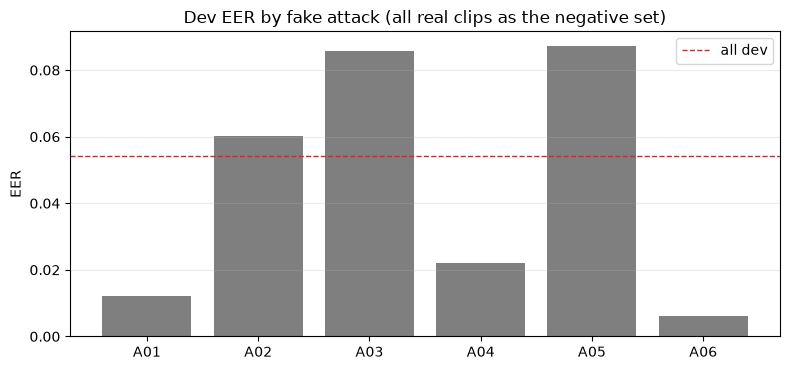

In [16]:
plot = attack_table[attack_table["attack"] != "all dev"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(plot["attack"], plot["eer"], color="tab:gray")
ax.axhline(attack_table.loc[attack_table["attack"] == "all dev", "eer"].iloc[0],
           color="tab:red", linestyle="--", linewidth=1, label="all dev")
ax.set_ylabel("EER")
ax.set_title("Dev EER by fake attack (all real clips as the negative set)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()


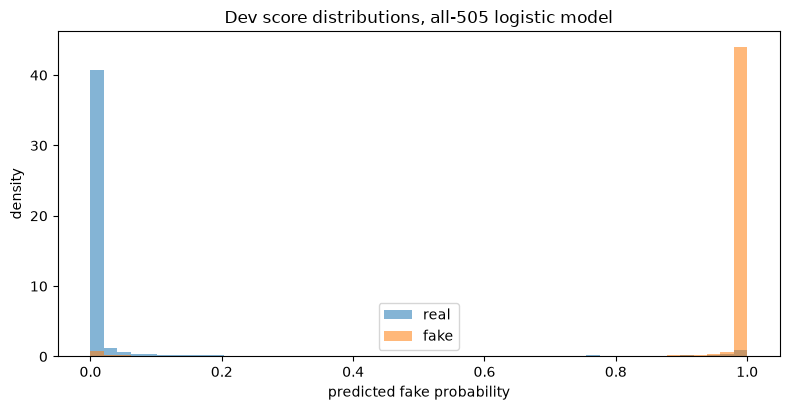

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 50)
ax.hist(all_scores[y_dev == REAL], bins=bins, density=True, alpha=0.55, label="real")
ax.hist(all_scores[y_dev == FAKE], bins=bins, density=True, alpha=0.55, label="fake")
ax.set_xlabel("predicted fake probability")
ax.set_ylabel("density")
ax.set_title("Dev score distributions, all-505 logistic model")
ax.legend()
plt.tight_layout()


## Saving the Result Tables

The tables are small. They are written under `features/4s/analysis/` so later notebooks can read them without rerunning the models.


In [18]:
out_dir = FEATURES_DIR / f"{CLIP_SECONDS:g}s" / "analysis"
out_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "logistic_C.csv": C_table,
    "baselines.csv": baseline_table,
    "group_alone.csv": group_table,
    "add_groups.csv": add_table,
    "remove_groups.csv": remove_table,
    "greedy_selection.csv": greedy_table,
    "selected_groups.csv": selected_table,
    "group_permutation.csv": perm_table,
    "attack_breakdown.csv": attack_table,
}
for name, table in tables.items():
    table.to_csv(out_dir / name, index=False)

print(f"saved {len(tables)} tables to {out_dir}")
print("selected groups:", ", ".join(selected))


saved 9 tables to /home/jackm/VishingDetector/features/4s/analysis
selected groups: lfcc, cqt, logmel, jitter_shimmer, spectral, pitch


## Summary

The signal is clearly multivariate. The best single number reaches only 0.731 dev AUC (32.9% EER), while using the groups together reaches 0.990 AUC / 5.4% EER. The shuffled-label control is 0.490 AUC, so this is not leakage.

| Model | Numbers | Dev AUC | Dev EER |
|---|---:|---:|---:|
| Best single number (`logmel:logmel79:mean`) | 1 | 0.731 | 32.9% |
| LFCC only | 40 | 0.959 | 10.4% |
| All groups, logistic | 505 | 0.990 | 5.4% |
| All groups, HGB | 505 | 0.991 | 4.6% |
| Greedy selected groups, logistic | 383 | 0.993 | 4.6% |

The greedy selected set is LFCC, CQT, log-mel, jitter/shimmer, spectral, and pitch; it drops MFCC and noise. Its dev AUC is slightly higher than all 505, but the EER intervals nearly overlap, so treat it as a simpler equivalent with a small possible gain rather than a proven improvement.

What adds signal:

- **LFCC is the core group.** Alone it gets 0.959 dev AUC; removing it from all features causes the largest loss (-0.006 AUC, +0.014 EER).
- **CQT is the clearest example of complementarity.** CQT alone is weak (0.748 AUC), but adding it to LFCC is the best single addition (+0.026 AUC), and shuffling the CQT group drops the all-feature model by 0.246 AUC. The summary statistics hide CQT's usefulness because they throw away time-frequency detail.
- **Log-mel also adds complementary signal.** Adding it to LFCC gives +0.024 AUC, and joint permutation drops the all-feature model by 0.227 AUC.
- **MFCC is mostly redundant.** It is strong alone (0.829 AUC), but adding it to LFCC gives only +0.017 AUC, its joint permutation drop is small (0.048), and removing it from all features slightly improves dev performance.
- **Noise has no usable signal.** Alone it is 0.525 AUC; adding it to LFCC gives +0.001; removing it barely changes anything. Pitch, jitter/shimmer, and spectral features add only small amounts.

Attack breakdown on dev is uneven: A01 1.2% EER, A04 2.2%, A06 0.6%, but A02 6.0%, A03 8.6%, and A05 8.7%. Dev contains the same A01-A06 attacks as train, so the final 2019 eval and 2021 results will be harder.

The next useful work is not more arbitrary handcrafted groups. The evidence points to:

1. Keep LFCC + CQT + log-mel as the core; drop MFCC and noise from compact models.
2. Add LFCC deltas, CQCC, and group-delay features, which are established ASVspoof front-ends.
3. Preserve full CQT/log-mel spectrograms for a CNN instead of mean/std summaries.
4. Add a frozen wav2vec2/HuBERT layer-wise baseline as the learned-representation ceiling.

No 2019 eval or 2021 data was loaded in this notebook.
